In [1]:
import pandas as pd
import pickle

In [2]:
df2 = pd.read_pickle('./data/df2.pickle')
df2

,id_admision,id_paciente,edad,genero,rural,fecha_admision,fecha_alta,tipo_admision,duracion_estancia,duracion_estancia_ci,...,cardiopatia_congenita,itu,sincope_neurocardiogenico,hipotension_ortostatica,endocarditis_infecciosa,tvp,shock_cardiogenico,shock,embolia_pulmonar,infeccion_pulmonar
0,1,234735,81,H,R,2022-04-01,2022-04-03,Urgencias,3,2,...,0,0,0,0,0,0,0,0,0,0
1,2,234696,65,H,R,2022-04-01,2022-04-05,Urgencias,5,2,...,0,0,0,0,0,0,0,0,0,0
2,3,234882,53,H,U,2022-04-01,2022-04-03,Urgencias,3,3,...,0,0,0,0,0,0,0,0,0,0
3,4,234635,67,M,U,2022-04-01,2022-04-08,Urgencias,8,6,...,0,0,0,0,0,0,0,0,0,0
4,5,234486,60,M,U,2022-04-01,2022-04-23,Urgencias,23,9,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15033,15753,699585,86,M,U,2024-03-31,2024-04-04,Consulta,5,1,...,0,0,0,0,0,0,0,0,0,0
15034,15754,699500,50,H,R,2024-03-31,2024-04-01,Urgencias,2,2,...,0,0,0,0,0,0,0,0,0,0
15035,15755,700415,82,H,U,2024-03-31,2024-04-09,Urgencias,10,5,...,0,0,0,0,0,0,0,0,0,0
15036,15756,699524,59,M,U,2024-03-31,2024-04-03,Consulta,4,2,...,0,0,0,0,0,0,0,0,0,0


In [3]:
# Ordenamos por paciente y fecha de admisión (por ejemplo, vemos que el 506 no ha tenido reingreso, el 798 si)
df2 = df2.sort_values(by=['id_paciente','fecha_admision'])
df2

,id_admision,id_paciente,edad,genero,rural,fecha_admision,fecha_alta,tipo_admision,duracion_estancia,duracion_estancia_ci,...,cardiopatia_congenita,itu,sincope_neurocardiogenico,hipotension_ortostatica,endocarditis_infecciosa,tvp,shock_cardiogenico,shock,embolia_pulmonar,infeccion_pulmonar
14573,15196,506,50,H,U,2024-03-07,2024-03-10,Consulta,4,0,...,0,1,0,0,0,0,0,0,0,0
77,93,798,71,H,U,2022-04-05,2022-04-06,Consulta,2,0,...,0,0,0,0,0,0,0,0,0,0
3476,3526,798,71,H,U,2022-05-10,2022-05-11,Consulta,2,0,...,0,0,0,0,0,0,0,0,0,0
14521,15111,798,72,H,U,2024-03-04,2024-03-09,Consulta,6,2,...,0,0,0,0,0,0,0,0,0,0
12549,12720,989,71,H,U,2023-05-12,2023-05-14,Urgencias,3,3,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8125,8284,4888078,49,H,U,2023-09-05,2023-09-06,Consulta,2,0,...,0,0,0,0,0,0,0,0,0,0
10478,10642,4888286,68,H,R,2023-09-09,2023-09-13,Consulta,5,2,...,0,0,0,0,0,0,0,0,0,0
8533,8693,4888926,65,M,U,2023-05-31,2023-06-01,Consulta,2,0,...,0,0,0,0,0,0,0,0,0,0
10314,10478,5711587,60,M,U,2023-08-30,2023-09-09,Consulta,11,7,...,0,0,0,0,0,0,0,0,0,0


## CREAR LA VARIABLE TARGET

Creamos una variable que nos indique si la admision es un reingreso del mismo paciente.

In [4]:
# Crear la nueva variable 'reingreso'
df2['reingreso'] = (df2['id_paciente'] == df2['id_paciente'].shift(1)).astype(int)

In [5]:
df2[ ['id_admision','id_paciente','resultado','reingreso']].head(10)

,id_admision,id_paciente,resultado,reingreso
14573,15196,506,Alta,0
77,93,798,Alta,0
3476,3526,798,Alta,1
14521,15111,798,Alta,1
12549,12720,989,Alta,0
12550,12721,989,Alta,1
11309,11477,989,Alta,1
6348,6500,1006,Defuncion,0
3983,4033,1060,Alta,0
4336,4386,1196,Alta,0


¿Qué porcentaje de readmisiones son reingresos?

In [6]:
df2.reingreso.sum() / len(df2) * 100

np.float64(21.558717914616306)

Análisis a nivel de paciente

In [7]:
reingresos_pacientes = df2.groupby('id_paciente').reingreso.sum()
reingresos_pacientes

id_paciente
506        0
798        2
989        2
1006       0
1060       0
          ..
4888078    0
4888286    0
4888926    0
5711587    0
6408503    0
Name: reingreso, Length: 11796, dtype: int64

In [8]:
reingresos_pacientes_agr = reingresos_pacientes.value_counts()
reingresos_pacientes_agr

reingreso
0     9370
1     1908
2      349
3      109
4       35
5       10
6        7
7        3
8        2
16       1
14       1
10       1
Name: count, dtype: int64

¿Qué porcentaje de pacientes tienen al menos un reingreso?

In [9]:
(1 - reingresos_pacientes_agr[0] / sum(reingresos_pacientes_agr)) * 100

np.float64(20.56629365886741)

¿Cual es la distribución de los reingresos?

In [10]:
reingresos_pacientes_agr_porc = reingresos_pacientes_agr / sum(reingresos_pacientes_agr) * 100
reingresos_pacientes_agr_porc

reingreso
0     79.433706
1     16.174975
2      2.958630
3      0.924042
4      0.296711
5      0.084774
6      0.059342
7      0.025432
8      0.016955
16     0.008477
14     0.008477
10     0.008477
Name: count, dtype: float64

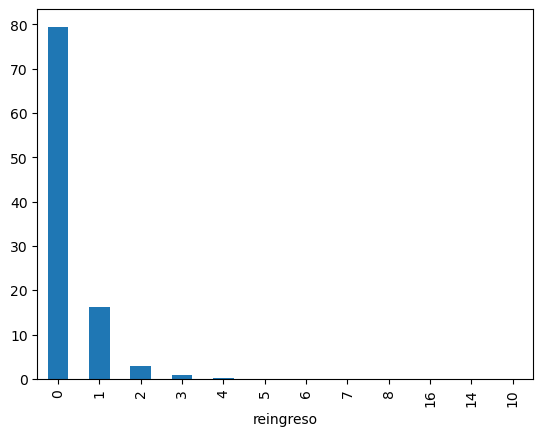

In [11]:
reingresos_pacientes_agr_porc.plot.bar();

## CREAR EL RISK SCORE

### PREPARACIÓN DE LA ESTRUCTURA DE DATOS

Vamos a crear un dataframe donde tengamos un vector de características junto con la variable target.

Eso implica que en aquellos pacientes que no tengan reingresos el resgistro se quedará tal cual está. 

Entendiendo que ese vector no ha llevado a un reingreso futuro.

Pero en aquellos pacientes que han tenido reingresos tenemos que poner en cada vector de caraterísticas la marca de que ese vector ha llevado a un reingreso futuro.

Eso nos permitirá intentar localizar qué características llevan más frecuentemente a un reingreso futuro.

In [12]:
risk = df2.copy()

In [13]:
risk['genera_reingreso'] = risk.reingreso.shift(-1)

In [14]:
risk[['id_admision','id_paciente','fecha_admision','fecha_alta','reingreso','genera_reingreso']].head(30)

,id_admision,id_paciente,fecha_admision,fecha_alta,reingreso,genera_reingreso
14573,15196,506,2024-03-07,2024-03-10,0,0.0
77,93,798,2022-04-05,2022-04-06,0,1.0
3476,3526,798,2022-05-10,2022-05-11,1,1.0
14521,15111,798,2024-03-04,2024-03-09,1,0.0
12549,12720,989,2023-05-12,2023-05-14,0,1.0
12550,12721,989,2023-05-12,2023-05-14,1,1.0
11309,11477,989,2023-10-15,2023-10-17,1,0.0
6348,6500,1006,2023-09-02,2023-10-29,0,0.0
3983,4033,1060,2022-11-01,2022-11-02,0,0.0
4336,4386,1196,2022-11-13,2022-11-21,0,0.0


Ahora bien, podría pasar que un vector no generara reingresos porque el paciente hubiera fallecido en esa admision, con lo cual aunque el vector fuera "malo" no podría generar reingreso por motivos obvios.

Por tanto tenemos que quitar esos casos para no sesgar la identificación de perfiles.

Si estuvieramos interesados en la mortalidad podríamos repetir este mismo análisis pero con la mortalidad como target.

In [15]:
risk = risk.loc[df2.resultado != 'Defuncion']

In [16]:
risk.resultado.value_counts()

resultado
Alta            13146
AltaNoMedica      838
Name: count, dtype: int64

### CREACION DE UN MINICUBO

1. Reducir dimensión indentificando las variables que pueden ser significativas

2. Convertir todas las variables a categóricas

3. Pasar a formato transaccional

4. Calcular la penetración de la target en cada variable-valor

### 1. Reducción de la dimensión

Eliminar las variables que no van a ser objeto de análisis.

In [17]:
eliminar = ['id_admision',
            'id_paciente',
            'fecha_admision',
            'fecha_alta',
            'reingreso']

In [18]:
risk2 = risk.drop(columns=eliminar)
risk2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13984 entries, 14573 to 10314
Data columns (total 52 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   edad                       13984 non-null  int64  
 1   genero                     13984 non-null  object 
 2   rural                      13984 non-null  object 
 3   tipo_admision              13984 non-null  object 
 4   duracion_estancia          13984 non-null  int64  
 5   duracion_estancia_ci       13984 non-null  int64  
 6   resultado                  13984 non-null  object 
 7   tabaquismo                 13984 non-null  int64  
 8   alcohol                    13984 non-null  int64  
 9   dm                         13984 non-null  int64  
 10  hta                        13984 non-null  int64  
 11  eac                        13984 non-null  int64  
 12  cardiomiopatia_previa      13984 non-null  int64  
 13  erc                        13984 non-null  int6

In [19]:
descriptivos = risk2.describe().T
descriptivos

,count,mean,std,min,25%,50%,75%,max
edad,13984.0,61.122926,13.351485,4.000,53.00,62.00,70.0,110.00
duracion_estancia,13984.0,6.495709,4.840573,1.000,3.00,5.00,8.0,98.00
duracion_estancia_ci,13984.0,3.758438,3.904843,0.000,1.00,3.00,5.0,48.00
tabaquismo,13984.0,0.053418,0.224874,0.000,0.00,0.00,0.0,1.00
alcohol,13984.0,0.069580,0.254446,0.000,0.00,0.00,0.0,1.00
dm,13984.0,0.306136,0.460903,0.000,0.00,0.00,1.0,1.00
hta,13984.0,0.494065,0.499983,0.000,0.00,0.00,1.0,1.00
eac,13984.0,0.686928,0.463760,0.000,0.00,1.00,1.0,1.00
cardiomiopatia_previa,13984.0,0.328375,0.469639,0.000,0.00,0.00,1.0,1.00
erc,13984.0,0.318507,0.465914,0.000,0.00,0.00,1.0,1.00


In [20]:
cero_uno = descriptivos[(descriptivos['min'] == 0) & (descriptivos['max'] == 1)].index.to_list()
cero_uno

['tabaquismo',
 'alcohol',
 'dm',
 'hta',
 'eac',
 'cardiomiopatia_previa',
 'erc',
 'enzimas_elevadas',
 'anemia_severa',
 'anemia',
 'angina_estable',
 'sca',
 'iamcest',
 'dolor_toracico',
 'insuficiencia_cardiaca',
 'icfer',
 'icfen',
 'valvular_cardiaca',
 'bavc',
 'sse',
 'lra',
 'acv_infarto',
 'acv_hemorragia',
 'fa',
 'tv',
 'tsvp',
 'cardiopatia_congenita',
 'itu',
 'sincope_neurocardiogenico',
 'hipotension_ortostatica',
 'endocarditis_infecciosa',
 'tvp',
 'shock_cardiogenico',
 'shock',
 'embolia_pulmonar',
 'infeccion_pulmonar',
 'genera_reingreso']

In [21]:
# Filtrar automáticamente las columnas de tipo 'object'
categorical_cols = risk2.select_dtypes(include=['object']).columns.to_list()

#Juntarlas a la lista de las cero_uno
categoricas = categorical_cols + cero_uno

categoricas

['genero',
 'rural',
 'tipo_admision',
 'resultado',
 'tabaquismo',
 'alcohol',
 'dm',
 'hta',
 'eac',
 'cardiomiopatia_previa',
 'erc',
 'enzimas_elevadas',
 'anemia_severa',
 'anemia',
 'angina_estable',
 'sca',
 'iamcest',
 'dolor_toracico',
 'insuficiencia_cardiaca',
 'icfer',
 'icfen',
 'valvular_cardiaca',
 'bavc',
 'sse',
 'lra',
 'acv_infarto',
 'acv_hemorragia',
 'fa',
 'tv',
 'tsvp',
 'cardiopatia_congenita',
 'itu',
 'sincope_neurocardiogenico',
 'hipotension_ortostatica',
 'endocarditis_infecciosa',
 'tvp',
 'shock_cardiogenico',
 'shock',
 'embolia_pulmonar',
 'infeccion_pulmonar',
 'genera_reingreso']

Necesitamos alguna prueba para priorizar las variables categóricas más significativas.

In [22]:
from scipy.stats import chi2_contingency
import pandas as pd

def chi_square_test(df, target_col, categorical_col):
    # Eliminar temporalmente los registros con NaN en la variable actual
    df_filtered = df.dropna(subset=[categorical_col])

    # Construir tabla de contingencia
    contingency_table = pd.crosstab(df_filtered[categorical_col], df_filtered[target_col])

    # Aplicar prueba de Chi-cuadrado
    chi2, p, dof, expected = chi2_contingency(contingency_table)
    
    return chi2, p, dof, expected

# Realizar la prueba de chi-cuadrado para cada variable categórica
results = {}

for var in categoricas:
    chi2, p, dof, expected = chi_square_test(risk2, 'genera_reingreso', var)
    results[var] = {'chi2': chi2, 'p': p}

# Crear un ranking basado en el valor de chi-cuadrado
ranking = pd.DataFrame.from_dict(results, orient='index').reset_index()
ranking.columns = ['Variable', 'Chi2', 'P-valor']
ranking = ranking.sort_values(by='Chi2', ascending=False).reset_index(drop=True)

# Imprimir el ranking
print("Ranking de significación de variables categóricas:")
print(ranking)



Ranking de significación de variables categóricas:
                     Variable          Chi2       P-valor
0            genera_reingreso  13978.375672  0.000000e+00
1      insuficiencia_cardiaca   3966.672997  0.000000e+00
2                       icfer   3750.981609  0.000000e+00
3                       icfen   3508.855665  0.000000e+00
4       cardiomiopatia_previa   3262.839227  0.000000e+00
5                         erc   2883.686942  0.000000e+00
6                         lra   2609.042256  0.000000e+00
7                          dm   2351.914595  0.000000e+00
8                     iamcest   2019.675230  0.000000e+00
9                         sca   1933.449222  0.000000e+00
10             angina_estable     33.673370  6.518698e-09
11                  resultado     28.609382  8.855210e-08
12             dolor_toracico     25.920491  3.557725e-07
13              tipo_admision     25.913469  3.570690e-07
14                    alcohol     22.011544  2.710155e-06
15           enzimas_

In [23]:
ranking[ranking['P-valor'] <= 0.01]

,Variable,Chi2,P-valor
0,genera_reingreso,13978.375672,0.000000e+00
1,insuficiencia_cardiaca,3966.672997,0.000000e+00
2,icfer,3750.981609,0.000000e+00
3,icfen,3508.855665,0.000000e+00
4,cardiomiopatia_previa,3262.839227,0.000000e+00
5,erc,2883.686942,0.000000e+00
6,lra,2609.042256,0.000000e+00
7,dm,2351.914595,0.000000e+00
8,iamcest,2019.675230,0.000000e+00
9,sca,1933.449222,0.000000e+00


In [24]:
# Dado que son demasiadas significativas y hay un corte muy claro nos quedaremos manualmente con las primeras
significativas_cat = ranking.Variable[1:10].to_list()
significativas_cat

['insuficiencia_cardiaca',
 'icfer',
 'icfen',
 'cardiomiopatia_previa',
 'erc',
 'lra',
 'dm',
 'iamcest',
 'sca']

Hacemos el análisis ahora con las continuas

In [25]:
df_continuas = risk2.loc[:, ~risk2.columns.isin(categoricas)]
df_continuas

,edad,duracion_estancia,duracion_estancia_ci,hb,leucocitos,plaquetas,glucosa,urea,creatinina,bnp,fe
14573,50,4,0,13.1,10.5,288.0,116.0,11.0,0.70,NaN,60.0
77,71,2,0,12.9,8.5,174.0,89.0,33.0,0.90,111.0,NaN
3476,71,2,0,12.9,8.5,174.0,89.0,33.0,0.90,111.0,NaN
14521,72,6,2,11.4,6.6,351.0,98.0,29.0,0.98,NaN,NaN
12549,71,3,3,10.5,8.2,210.0,192.0,50.0,1.45,787.0,46.0
...,...,...,...,...,...,...,...,...,...,...,...
7028,55,6,3,14.6,16.8,199.0,101.0,21.0,0.70,36.0,38.0
8125,49,2,0,15.7,9.0,303.0,140.0,17.0,0.78,NaN,60.0
10478,68,5,2,12.2,6.7,208.0,116.0,27.0,0.70,78.0,60.0
8533,65,2,0,11.3,11.3,175.0,211.0,26.0,0.70,84.0,60.0


In [26]:
from scipy.stats import ttest_ind

# Lista para almacenar las variables significativas
significativas_con = []

# Iterar sobre cada variable continua
for col in df_continuas.columns:
    # Eliminar temporalmente los registros con NaN en la variable actual
    df_filtered = df_continuas.dropna(subset=[col])

    # Dividir en los dos grupos según 'genera_reingreso'
    group1 = df_filtered[risk2.loc[df_filtered.index, 'genera_reingreso'] == 0][col]
    group2 = df_filtered[risk2.loc[df_filtered.index, 'genera_reingreso'] == 1][col]
    
    # Verificar que ambos grupos tengan datos suficientes
    if len(group1) > 30 and len(group2) > 30:
        # Prueba T
        t_stat, p_value = ttest_ind(group1, group2, equal_var=True)
        
        # Diagnóstico
        if p_value < 0.01:  # Nivel de significancia del 1%
            diagnosis = "Significativa"
            significativas_con.append(col)  # Agregar a la lista de significativas
        else:
            diagnosis = "No significativa"
    else:
        t_stat, p_value, diagnosis = None, None, "No calculable (pocos datos)"
    
    print(f"Variable: {col}, T-statistic: {t_stat}, p-value: {p_value}, Diagnóstico: {diagnosis}")

# Mostrar la lista de variables significativas
print("\nVariables significativas:")
print(significativas_con)



Variable: edad, T-statistic: -9.75373394093266, p-value: 2.0959168884626232e-22, Diagnóstico: Significativa
Variable: duracion_estancia, T-statistic: -10.602706836644197, p-value: 3.638808956496968e-26, Diagnóstico: Significativa
Variable: duracion_estancia_ci, T-statistic: -7.87653068774845, p-value: 3.612963397275472e-15, Diagnóstico: Significativa
Variable: hb, T-statistic: 7.716855447708306, p-value: 1.2732633566929145e-14, Diagnóstico: Significativa
Variable: leucocitos, T-statistic: -0.054403940647303445, p-value: 0.9566141219223421, Diagnóstico: No significativa
Variable: plaquetas, T-statistic: -0.27357486132533043, p-value: 0.7844154243695063, Diagnóstico: No significativa
Variable: glucosa, T-statistic: -4.765912068969017, p-value: 1.8999151605301494e-06, Diagnóstico: Significativa
Variable: urea, T-statistic: -10.123993625012412, p-value: 5.237329882275124e-24, Diagnóstico: Significativa
Variable: creatinina, T-statistic: -5.777438899148076, p-value: 7.747103699796292e-09, D

NOTA: por simplicidad del caso solo nos quedaremos con las 3 continuas más significativas.

In [27]:
significativas = significativas_cat + significativas_con[:3]
significativas

['insuficiencia_cardiaca',
 'icfer',
 'icfen',
 'cardiomiopatia_previa',
 'erc',
 'lra',
 'dm',
 'iamcest',
 'sca',
 'edad',
 'duracion_estancia',
 'duracion_estancia_ci']

### 2. Discretizacion de las variables continuas

In [28]:
disc_df = risk2[['edad','duracion_estancia','duracion_estancia_ci','genera_reingreso']].copy()
disc_df

,edad,duracion_estancia,duracion_estancia_ci,genera_reingreso
14573,50,4,0,0.0
77,71,2,0,1.0
3476,71,2,0,1.0
14521,72,6,2,0.0
12549,71,3,3,1.0
...,...,...,...,...
7028,55,6,3,0.0
8125,49,2,0,0.0
10478,68,5,2,0.0
8533,65,2,0,0.0


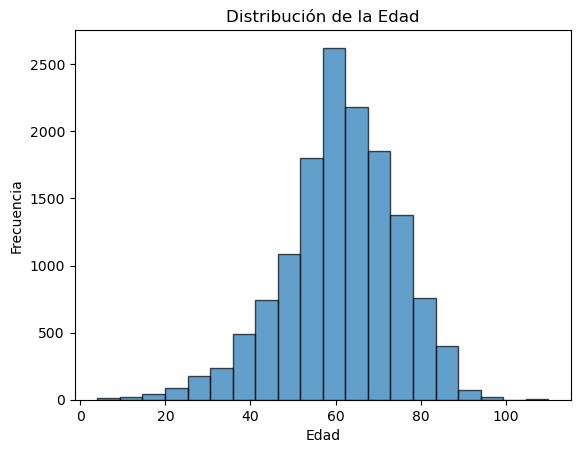

In [29]:
import matplotlib.pyplot as plt

# Paso 1: Crear un histograma inicial de la edad
plt.hist(disc_df['edad'], bins=20, edgecolor='k', alpha=0.7)
plt.title('Distribución de la Edad')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()


Opcion con Seaborn:

Una forma de ver muy claramente donde hacer los cortes es normalizar los tramos del histograma a máximo 100.

Con Matplotlib se puede hacer pero es complicado.

Vamos a usar otra librería gráfica, llamada Seaborn, con la que resulta más sencillo.

Podemos apoyarnos en la IA para crear los gráficos:

In [30]:
disc_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13984 entries, 14573 to 10314
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   edad                  13984 non-null  int64  
 1   duracion_estancia     13984 non-null  int64  
 2   duracion_estancia_ci  13984 non-null  int64  
 3   genera_reingreso      13984 non-null  float64
dtypes: float64(1), int64(3)
memory usage: 1.0 MB


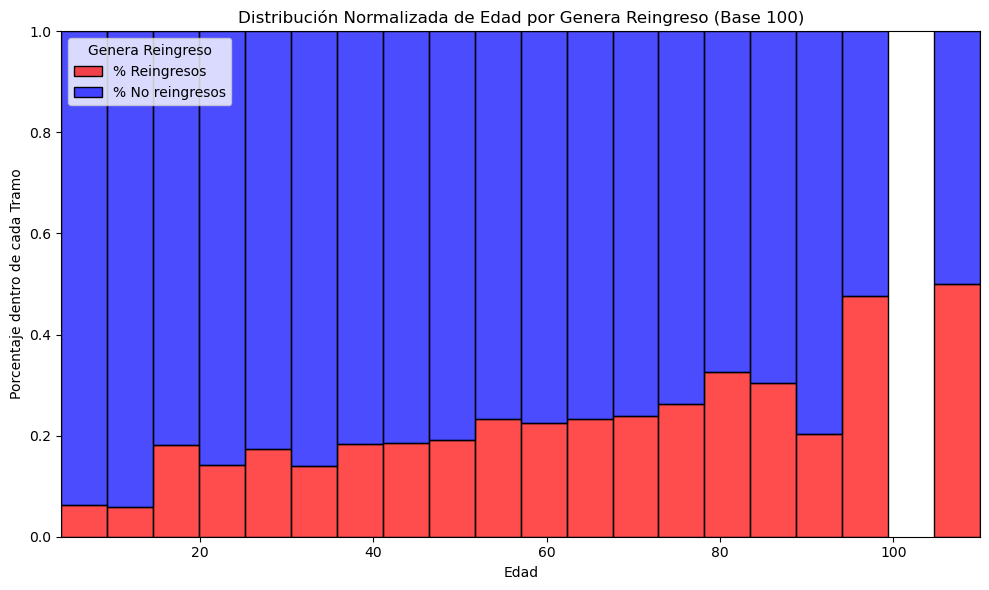

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

# Crear ela
plt.figure(figsize=(10, 6))
sns.histplot(
    data=disc_df,
    x='edad',
    hue='genera_reingreso',
    bins=20,
    stat='percent',  # Mostrar los datos como porcentaje
    multiple='fill',  # Normalizar cada barra al 100%
    palette=['blue', 'red'], 
    edgecolor='k',
    alpha=0.7
)

# Personalización del gráfico
plt.title('Distribución Normalizada de Edad por Genera Reingreso (Base 100)')
plt.xlabel('Edad')
plt.ylabel('Porcentaje dentro de cada Tramo')
plt.legend(title='Genera Reingreso', labels=['% Reingresos','% No reingresos'])
plt.tight_layout()

# Mostrar el gráfico
plt.show()



C:\Users\usuario\AppData\Local\Temp\ipykernel_22436\4180686347.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disc_df.groupby('edad_disc')['genera_reingreso']


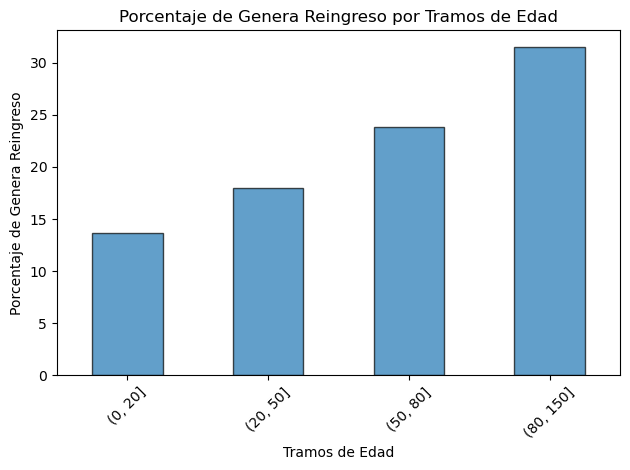

In [32]:
# Paso 2: Crear cortes manuales para discretizar la edad
edad_cortes = [0, 20, 50, 80, 150] 
disc_df['edad_disc'] = pd.cut(disc_df['edad'], bins=edad_cortes)

# Calcular el porcentaje de genera_reingreso en cada tramo de edad
porcentajes = (
    disc_df.groupby('edad_disc')['genera_reingreso']
    .mean() * 100  # Convertir a porcentaje
)

# Paso 3: Visualizar el porcentaje de genera_reingreso por tramos de edad
porcentajes.plot(kind='bar', edgecolor='k', alpha=0.7)
plt.title('Porcentaje de Genera Reingreso por Tramos de Edad')
plt.xlabel('Tramos de Edad')
plt.ylabel('Porcentaje de Genera Reingreso')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

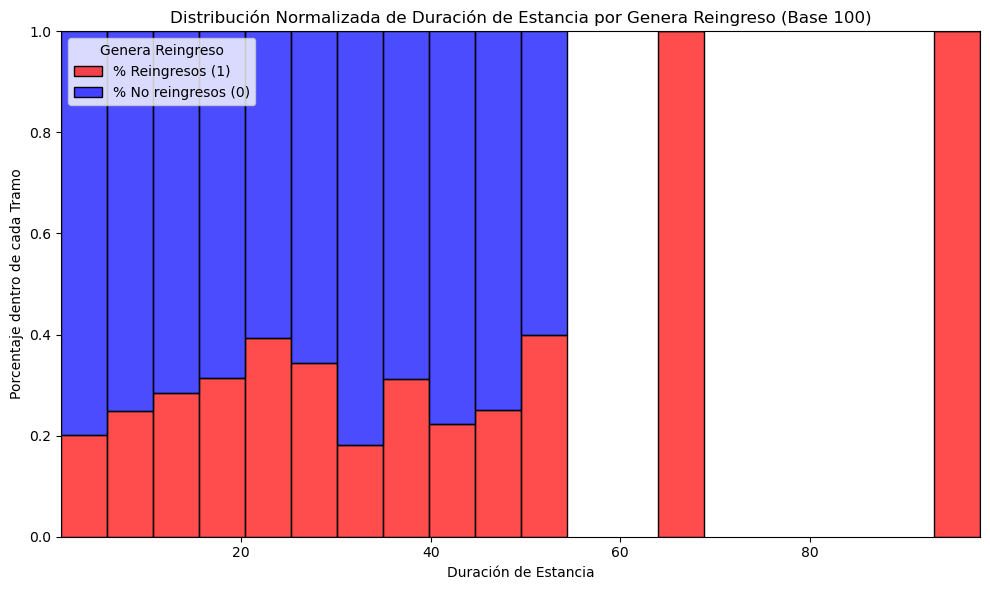

In [33]:
# Duración de estancia
plt.figure(figsize=(10, 6))
sns.histplot(
    data=disc_df,
    x='duracion_estancia',
    hue='genera_reingreso',
    bins=20,
    stat='percent',  # Mostrar los datos como porcentaje
    multiple='fill',  # Normalizar cada barra al 100%
    palette=['blue', 'red'],  # Colores para 0 y 1
    edgecolor='k',
    alpha=0.7
)

# Personalización del gráfico
plt.title('Distribución Normalizada de Duración de Estancia por Genera Reingreso (Base 100)')
plt.xlabel('Duración de Estancia')
plt.ylabel('Porcentaje dentro de cada Tramo')
plt.legend(title='Genera Reingreso', labels=['% Reingresos (1)','% No reingresos (0)'])
plt.tight_layout()

# Mostrar el gráfico
plt.show()


C:\Users\usuario\AppData\Local\Temp\ipykernel_22436\1741635621.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disc_df.groupby('duracion_estancia_disc')['genera_reingreso']


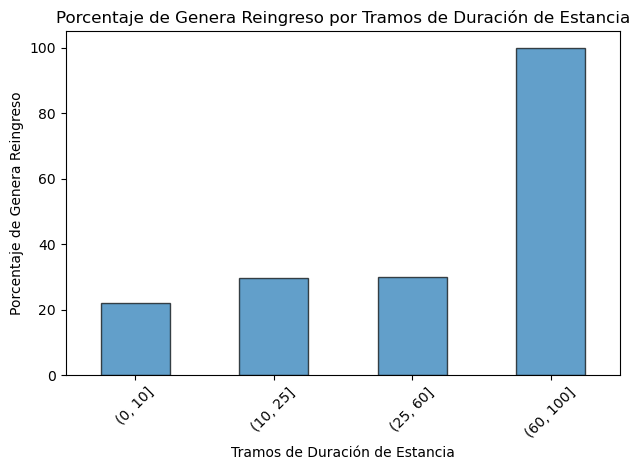

In [34]:
# Paso 2: Crear cortes manuales para discretizar la duración de estancia
estancia_cortes = [0, 10, 25, 60, 100]
disc_df['duracion_estancia_disc'] = pd.cut(disc_df['duracion_estancia'], bins=estancia_cortes, right = True)

# Calcular el porcentaje de genera_reingreso en cada tramo de duración de estancia
porcentajes = (
    disc_df.groupby('duracion_estancia_disc')['genera_reingreso']
    .mean() * 100  # Convertir a porcentaje
)

# Paso 3: Visualizar el porcentaje de genera_reingreso por tramos de duración de estancia
porcentajes.plot(kind='bar', edgecolor='k', alpha=0.7)
plt.title('Porcentaje de Genera Reingreso por Tramos de Duración de Estancia')
plt.xlabel('Tramos de Duración de Estancia')
plt.ylabel('Porcentaje de Genera Reingreso')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

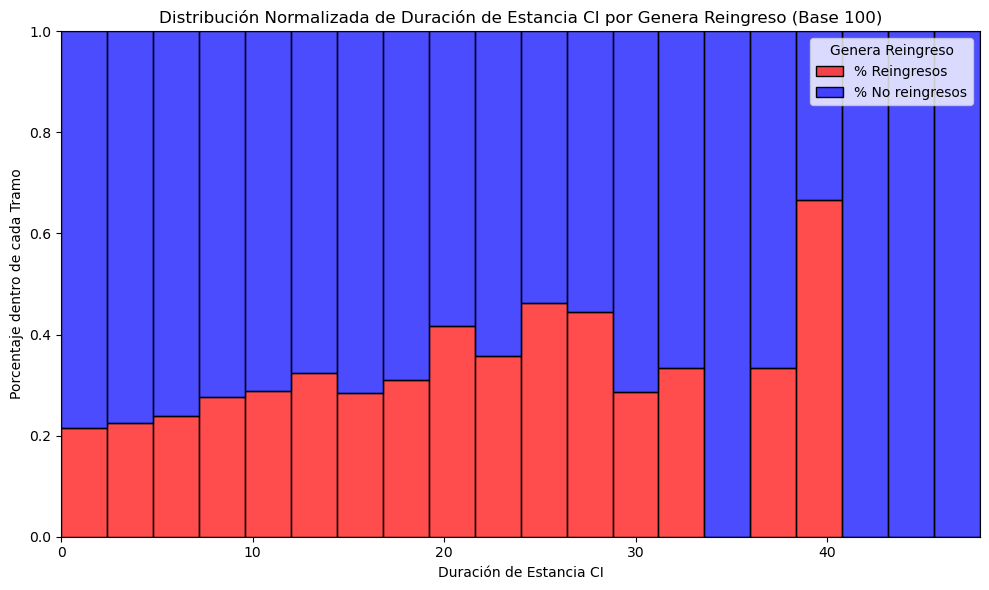

In [35]:
# Duración de estancia CI
plt.figure(figsize=(10, 6))
sns.histplot(
    data=disc_df,
    x='duracion_estancia_ci',
    hue='genera_reingreso',
    bins=20,
    stat='percent',  # Mostrar los datos como porcentaje
    multiple='fill',  # Normalizar cada barra al 100%
    palette=['blue', 'red'],  # Colores para 0 y 1
    edgecolor='k',
    alpha=0.7
)

# Personalización del gráfico
plt.title('Distribución Normalizada de Duración de Estancia CI por Genera Reingreso (Base 100)')
plt.xlabel('Duración de Estancia CI')
plt.ylabel('Porcentaje dentro de cada Tramo')
plt.legend(title='Genera Reingreso', labels=['% Reingresos','% No reingresos'])
plt.tight_layout()

# Mostrar el gráfico
plt.show()


C:\Users\usuario\AppData\Local\Temp\ipykernel_22436\3472072696.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disc_df.groupby('duracion_estancia_ci_disc')['genera_reingreso']


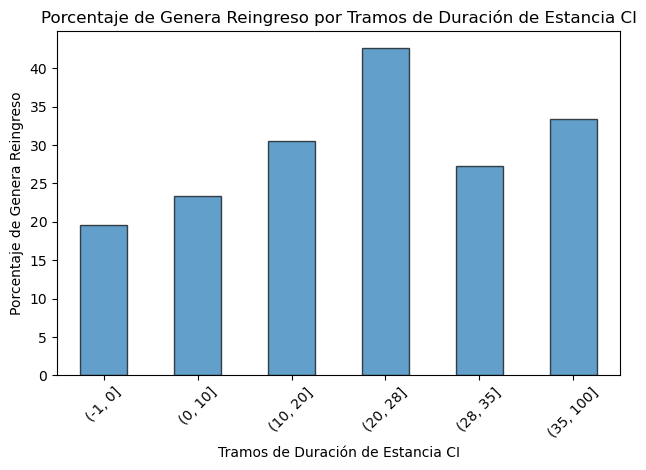

In [36]:
# Paso 2: Crear cortes manuales para discretizar la duración de estancia CI
# Ajusta los intervalos según lo que observes en el histograma
estancia_cortes = [-1, 0, 10, 20, 28, 35, 100]#ponemos el -1 para que coja los ceros ya que son abiertos por abajo
disc_df['duracion_estancia_ci_disc'] = pd.cut(disc_df['duracion_estancia_ci'], bins=estancia_cortes, right=True)

# Calcular el porcentaje de genera_reingreso en cada tramo de duración de estancia CI
porcentajes = (
    disc_df.groupby('duracion_estancia_ci_disc')['genera_reingreso']
    .mean() * 100  # Convertir a porcentaje
)

# Paso 3: Visualizar el porcentaje de genera_reingreso por tramos de duración de estancia CI
porcentajes.plot(kind='bar', edgecolor='k', alpha=0.7)
plt.title('Porcentaje de Genera Reingreso por Tramos de Duración de Estancia CI')
plt.xlabel('Tramos de Duración de Estancia CI')
plt.ylabel('Porcentaje de Genera Reingreso')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [37]:
disc_df

,edad,duracion_estancia,duracion_estancia_ci,genera_reingreso,edad_disc,duracion_estancia_disc,duracion_estancia_ci_disc
14573,50,4,0,0.0,"(20, 50]","(0, 10]","(-1, 0]"
77,71,2,0,1.0,"(50, 80]","(0, 10]","(-1, 0]"
3476,71,2,0,1.0,"(50, 80]","(0, 10]","(-1, 0]"
14521,72,6,2,0.0,"(50, 80]","(0, 10]","(0, 10]"
12549,71,3,3,1.0,"(50, 80]","(0, 10]","(0, 10]"
...,...,...,...,...,...,...,...
7028,55,6,3,0.0,"(50, 80]","(0, 10]","(0, 10]"
8125,49,2,0,0.0,"(20, 50]","(0, 10]","(-1, 0]"
10478,68,5,2,0.0,"(50, 80]","(0, 10]","(0, 10]"
8533,65,2,0,0.0,"(50, 80]","(0, 10]","(-1, 0]"


Volvemos a risk2, eliminamos las variables que no se van a usar en el minicubo y añadimos las discretizadas.

### 3. Crear el minicubo

In [38]:
minicubo = risk2.copy()

In [39]:
minicubo

,edad,genero,rural,tipo_admision,duracion_estancia,duracion_estancia_ci,resultado,tabaquismo,alcohol,dm,...,itu,sincope_neurocardiogenico,hipotension_ortostatica,endocarditis_infecciosa,tvp,shock_cardiogenico,shock,embolia_pulmonar,infeccion_pulmonar,genera_reingreso
14573,50,H,U,Consulta,4,0,Alta,0,0,0,...,1,0,0,0,0,0,0,0,0,0.0
77,71,H,U,Consulta,2,0,Alta,0,0,1,...,0,0,0,0,0,0,0,0,0,1.0
3476,71,H,U,Consulta,2,0,Alta,0,0,0,...,0,0,0,0,0,0,0,0,0,1.0
14521,72,H,U,Consulta,6,2,Alta,0,0,0,...,0,0,0,0,0,0,0,0,0,0.0
12549,71,H,U,Urgencias,3,3,Alta,0,0,1,...,0,0,0,0,0,0,0,0,0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7028,55,H,U,Urgencias,6,3,Alta,1,0,1,...,0,0,0,0,0,0,0,0,0,0.0
8125,49,H,U,Consulta,2,0,Alta,0,1,1,...,0,0,0,0,0,0,0,0,0,0.0
10478,68,H,R,Consulta,5,2,Alta,0,0,0,...,0,0,0,0,0,0,0,0,0,0.0
8533,65,M,U,Consulta,2,0,Alta,0,0,0,...,0,0,0,0,0,0,0,0,0,0.0


In [40]:
a_mantener = significativas + ['genera_reingreso']
a_mantener

['insuficiencia_cardiaca',
 'icfer',
 'icfen',
 'cardiomiopatia_previa',
 'erc',
 'lra',
 'dm',
 'iamcest',
 'sca',
 'edad',
 'duracion_estancia',
 'duracion_estancia_ci',
 'genera_reingreso']

In [41]:
#quedarnos con las significativas
minicubo = minicubo.loc[:, minicubo.columns.isin(a_mantener)]
minicubo

,edad,duracion_estancia,duracion_estancia_ci,dm,cardiomiopatia_previa,erc,sca,iamcest,insuficiencia_cardiaca,icfer,icfen,lra,genera_reingreso
14573,50,4,0,0,1,1,0,0,1,1,1,1,0.0
77,71,2,0,1,1,1,0,1,1,0,1,0,1.0
3476,71,2,0,0,0,0,0,0,1,1,0,0,1.0
14521,72,6,2,0,0,0,0,0,0,1,0,0,0.0
12549,71,3,3,1,1,0,1,1,0,1,1,1,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7028,55,6,3,1,1,0,0,0,1,0,0,1,0.0
8125,49,2,0,1,0,0,0,0,0,0,0,1,0.0
10478,68,5,2,0,0,1,0,1,0,0,0,0,0.0
8533,65,2,0,0,0,1,0,1,1,0,0,0,0.0


In [42]:
# añadir las versiones discretizadas
minicubo = pd.concat([minicubo, disc_df[['edad_disc','duracion_estancia_disc','duracion_estancia_ci_disc']]], axis = 1)
minicubo

,edad,duracion_estancia,duracion_estancia_ci,dm,cardiomiopatia_previa,erc,sca,iamcest,insuficiencia_cardiaca,icfer,icfen,lra,genera_reingreso,edad_disc,duracion_estancia_disc,duracion_estancia_ci_disc
14573,50,4,0,0,1,1,0,0,1,1,1,1,0.0,"(20, 50]","(0, 10]","(-1, 0]"
77,71,2,0,1,1,1,0,1,1,0,1,0,1.0,"(50, 80]","(0, 10]","(-1, 0]"
3476,71,2,0,0,0,0,0,0,1,1,0,0,1.0,"(50, 80]","(0, 10]","(-1, 0]"
14521,72,6,2,0,0,0,0,0,0,1,0,0,0.0,"(50, 80]","(0, 10]","(0, 10]"
12549,71,3,3,1,1,0,1,1,0,1,1,1,1.0,"(50, 80]","(0, 10]","(0, 10]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7028,55,6,3,1,1,0,0,0,1,0,0,1,0.0,"(50, 80]","(0, 10]","(0, 10]"
8125,49,2,0,1,0,0,0,0,0,0,0,1,0.0,"(20, 50]","(0, 10]","(-1, 0]"
10478,68,5,2,0,0,1,0,1,0,0,0,0,0.0,"(50, 80]","(0, 10]","(0, 10]"
8533,65,2,0,0,0,1,0,1,1,0,0,0,0.0,"(50, 80]","(0, 10]","(-1, 0]"


In [43]:
# eliminar las continuas 
minicubo.drop(columns = ['edad','duracion_estancia','duracion_estancia_ci'], inplace = True)
minicubo

,dm,cardiomiopatia_previa,erc,sca,iamcest,insuficiencia_cardiaca,icfer,icfen,lra,genera_reingreso,edad_disc,duracion_estancia_disc,duracion_estancia_ci_disc
14573,0,1,1,0,0,1,1,1,1,0.0,"(20, 50]","(0, 10]","(-1, 0]"
77,1,1,1,0,1,1,0,1,0,1.0,"(50, 80]","(0, 10]","(-1, 0]"
3476,0,0,0,0,0,1,1,0,0,1.0,"(50, 80]","(0, 10]","(-1, 0]"
14521,0,0,0,0,0,0,1,0,0,0.0,"(50, 80]","(0, 10]","(0, 10]"
12549,1,1,0,1,1,0,1,1,1,1.0,"(50, 80]","(0, 10]","(0, 10]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7028,1,1,0,0,0,1,0,0,1,0.0,"(50, 80]","(0, 10]","(0, 10]"
8125,1,0,0,0,0,0,0,0,1,0.0,"(20, 50]","(0, 10]","(-1, 0]"
10478,0,0,1,0,1,0,0,0,0,0.0,"(50, 80]","(0, 10]","(0, 10]"
8533,0,0,1,0,1,1,0,0,0,0.0,"(50, 80]","(0, 10]","(-1, 0]"


Pasamos a transaccional.

In [76]:
minicubo = minicubo.melt(id_vars = 'genera_reingreso')
minicubo

,genera_reingreso,variable,value
0,0.0,dm,0
1,1.0,dm,1
2,1.0,dm,0
3,0.0,dm,0
4,1.0,dm,1
...,...,...,...
167803,0.0,duracion_estancia_ci_disc,"(0, 10]"
167804,0.0,duracion_estancia_ci_disc,"(-1, 0]"
167805,0.0,duracion_estancia_ci_disc,"(0, 10]"
167806,0.0,duracion_estancia_ci_disc,"(-1, 0]"


Los tramos nos van a dar problemas de formato. Por ello vamos a convertir todo lo de la columna value a cadenas.

In [77]:
minicubo['value'] = minicubo['value'].astype(str)
minicubo

,genera_reingreso,variable,value
0,0.0,dm,0
1,1.0,dm,1
2,1.0,dm,0
3,0.0,dm,0
4,1.0,dm,1
...,...,...,...
167803,0.0,duracion_estancia_ci_disc,"(0, 10]"
167804,0.0,duracion_estancia_ci_disc,"(-1, 0]"
167805,0.0,duracion_estancia_ci_disc,"(0, 10]"
167806,0.0,duracion_estancia_ci_disc,"(-1, 0]"


In [78]:
minicubo = minicubo.groupby(['variable','value']).genera_reingreso.mean().reset_index()
minicubo

,variable,value,genera_reingreso
0,cardiomiopatia_previa,0,0.088799
1,cardiomiopatia_previa,1,0.522648
2,dm,0,0.116356
3,dm,1,0.491708
4,duracion_estancia_ci_disc,"(-1, 0]",0.195687
5,duracion_estancia_ci_disc,"(0, 10]",0.233819
6,duracion_estancia_ci_disc,"(10, 20]",0.305785
7,duracion_estancia_ci_disc,"(20, 28]",0.426667
8,duracion_estancia_ci_disc,"(28, 35]",0.272727
9,duracion_estancia_ci_disc,"(35, 100]",0.333333


Podemos hacer un código sencillo para generar automaticamente los gráficos de todas las variables.

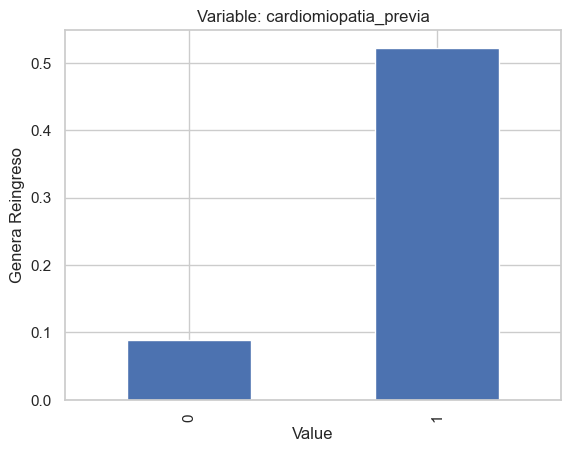

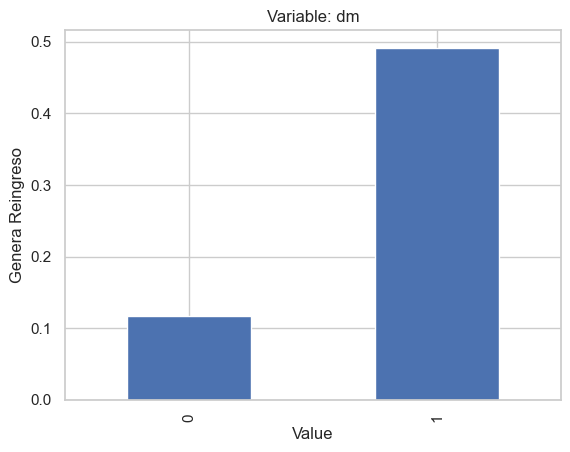

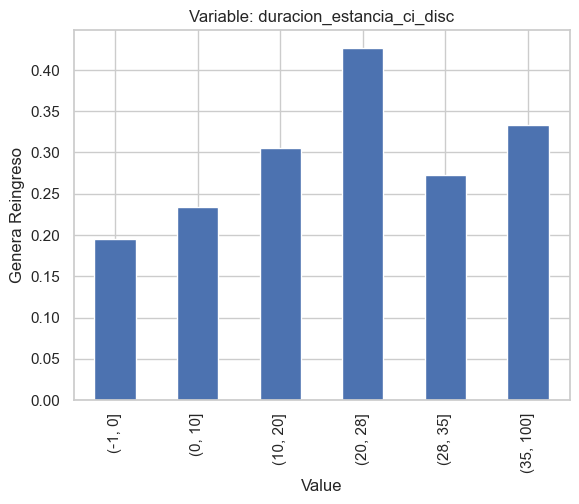

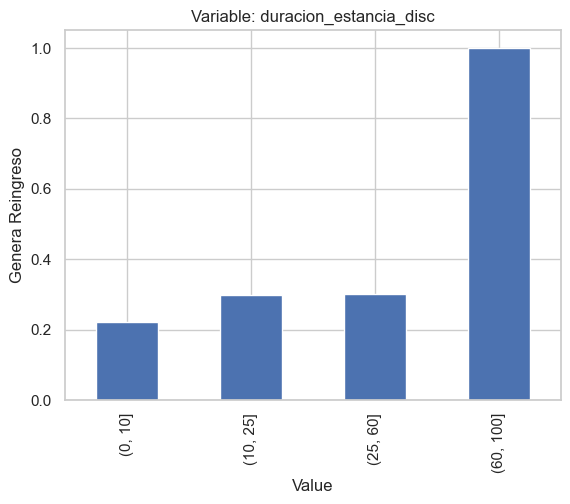

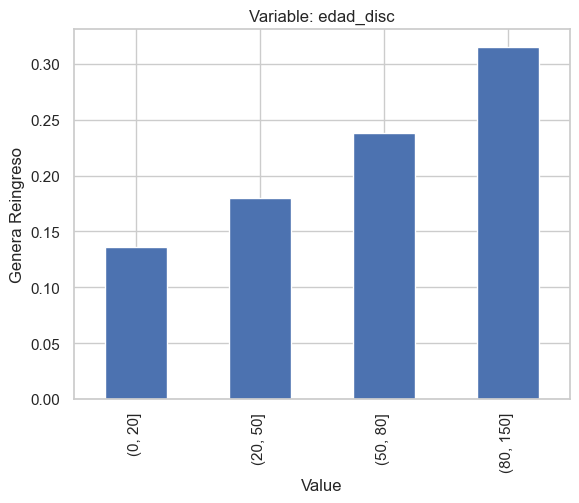

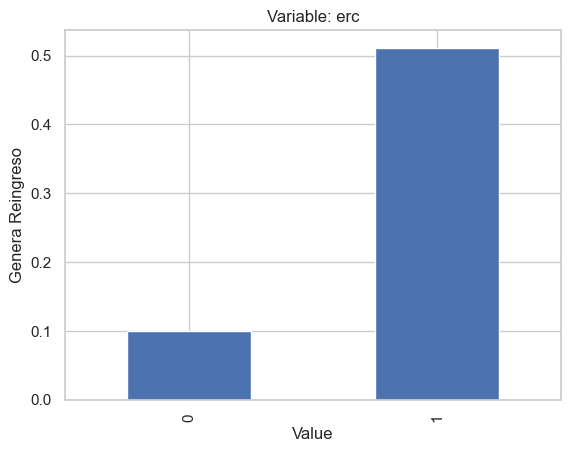

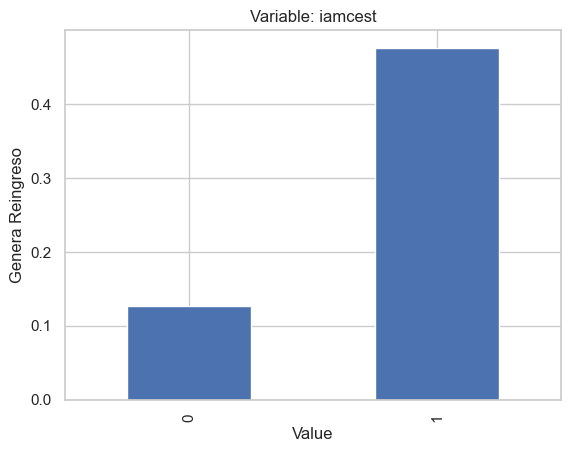

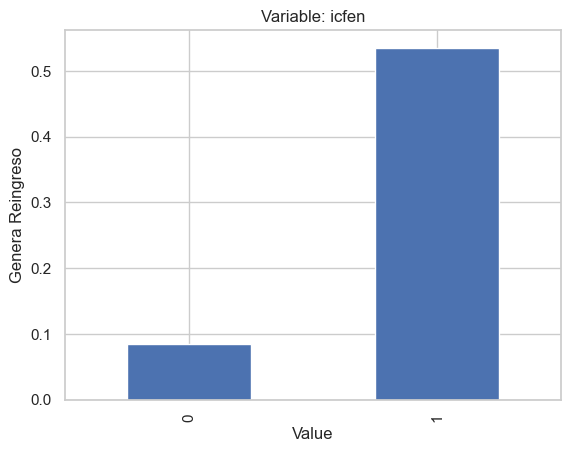

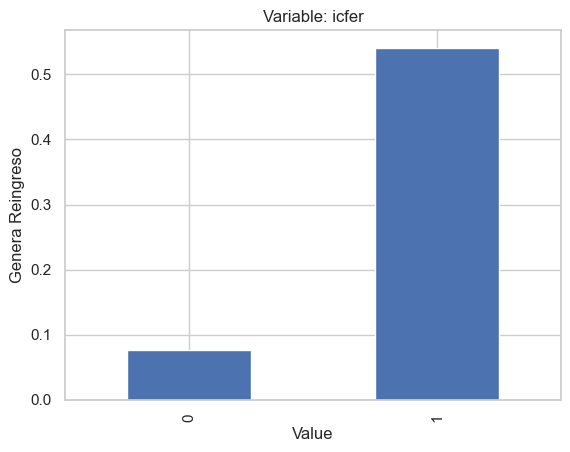

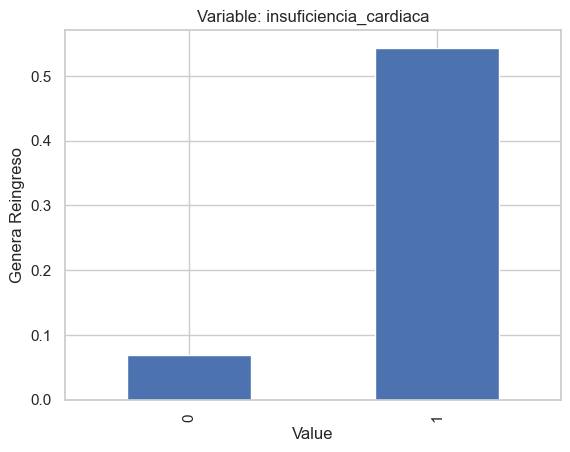

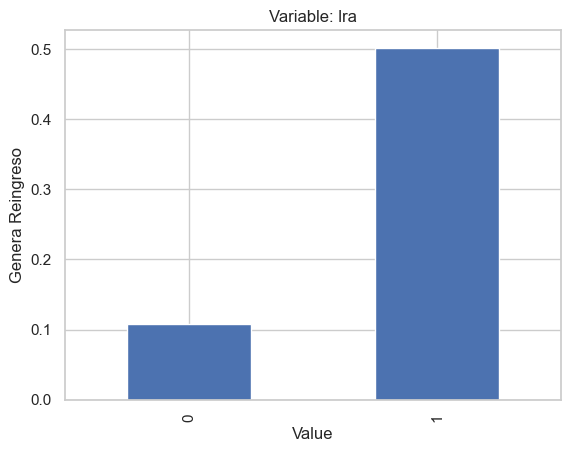

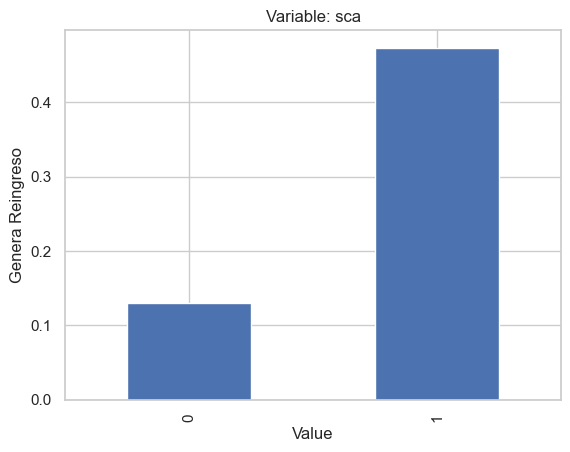

In [79]:
# Iterar sobre las variables únicas en la columna 'variable'
for variable in minicubo['variable'].unique():
    # Filtrar las filas correspondientes a la variable actual
    subset = minicubo[minicubo['variable'] == variable]
    
    # Crear el gráfico de barras
    subset.plot.bar(x='value', y='genera_reingreso', legend=False)
    
    # Agregar título y etiquetas
    plt.title(f'Variable: {variable}')
    plt.xlabel('Value')
    plt.ylabel('Genera Reingreso')
    
    # Mostrar el gráfico
    plt.show();


### CREACION DEL RISK SCORECARD

In [44]:
rsc = minicubo.copy()

In [45]:
rsc['puntos'] = (rsc.genera_reingreso * 100).astype('int')
rsc

,dm,cardiomiopatia_previa,erc,sca,iamcest,insuficiencia_cardiaca,icfer,icfen,lra,genera_reingreso,edad_disc,duracion_estancia_disc,duracion_estancia_ci_disc,puntos
14573,0,1,1,0,0,1,1,1,1,0.0,"(20, 50]","(0, 10]","(-1, 0]",0
77,1,1,1,0,1,1,0,1,0,1.0,"(50, 80]","(0, 10]","(-1, 0]",100
3476,0,0,0,0,0,1,1,0,0,1.0,"(50, 80]","(0, 10]","(-1, 0]",100
14521,0,0,0,0,0,0,1,0,0,0.0,"(50, 80]","(0, 10]","(0, 10]",0
12549,1,1,0,1,1,0,1,1,1,1.0,"(50, 80]","(0, 10]","(0, 10]",100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7028,1,1,0,0,0,1,0,0,1,0.0,"(50, 80]","(0, 10]","(0, 10]",0
8125,1,0,0,0,0,0,0,0,1,0.0,"(20, 50]","(0, 10]","(-1, 0]",0
10478,0,0,1,0,1,0,0,0,0,0.0,"(50, 80]","(0, 10]","(0, 10]",0
8533,0,0,1,0,1,1,0,0,0,0.0,"(50, 80]","(0, 10]","(-1, 0]",0


In [46]:

def calcular_scoring(registro):
    scoring = 0  # Inicializamos el scoring en 0
    
    # Reglas para calcular el puntaje basado en la tabla dada
    if registro.get("cardiomiopatia_previa") == 1:
        scoring += 52
    else:
        scoring += 8

    if registro.get("dm") == 1:
        scoring += 49
    else:
        scoring += 11

    if "duracion_estancia_ci_disc" in registro:
        duracion_estancia_ci_disc = registro["duracion_estancia_ci_disc"]
        if duracion_estancia_ci_disc in ["(-1, 0]", "(0, 10]"]:
            scoring += 19 if duracion_estancia_ci_disc == "(-1, 0]" else 23
        elif duracion_estancia_ci_disc == "(10, 20]":
            scoring += 30
        elif duracion_estancia_ci_disc == "(20, 28]":
            scoring += 42
        elif duracion_estancia_ci_disc == "(28, 35]":
            scoring += 27
        elif duracion_estancia_ci_disc == "(35, 100]":
            scoring += 33

    if "duracion_estancia_disc" in registro:
        duracion_estancia_disc = registro["duracion_estancia_disc"]
        if duracion_estancia_disc == "(0, 10]":
            scoring += 22
        elif duracion_estancia_disc == "(10, 25]":
            scoring += 29
        elif duracion_estancia_disc == "(25, 60]":
            scoring += 30
        elif duracion_estancia_disc == "(60, 100]":
            scoring += 100

    if "edad_disc" in registro:
        edad_disc = registro["edad_disc"]
        if edad_disc == "(0, 20]":
            scoring += 13
        elif edad_disc == "(20, 50]":
            scoring += 17
        elif edad_disc == "(50, 80]":
            scoring += 23
        elif edad_disc == "(80, 150]":
            scoring += 31

    if registro.get("erc") == 1:
        scoring += 51
    else:
        scoring += 10
    
    if registro.get("iamcest") == 1:
        scoring += 47
    else:
        scoring += 12
    
    if registro.get("icfen") == 1:
        scoring += 53
    else:
        scoring += 8
    
    if registro.get("icfer") == 1:
        scoring += 54
    else:
        scoring += 7
    
    if registro.get("insuficiencia_cardiaca") == 1:
        scoring += 54
    else:
        scoring += 6
    
    if registro.get("lra") == 1:
        scoring += 50
    else:
        scoring += 10
    
    if registro.get("sca") == 1:
        scoring += 47
    else:
        scoring += 12
    
    return scoring

In [47]:
# Aplicar la función a cada registro del DataFrame risk
risk['scoring'] = risk.apply(calcular_scoring, axis=1)

In [48]:
risk

,id_admision,id_paciente,edad,genero,rural,fecha_admision,fecha_alta,tipo_admision,duracion_estancia,duracion_estancia_ci,...,hipotension_ortostatica,endocarditis_infecciosa,tvp,shock_cardiogenico,shock,embolia_pulmonar,infeccion_pulmonar,reingreso,genera_reingreso,scoring
14573,15196,506,50,H,U,2024-03-07,2024-03-10,Consulta,4,0,...,0,0,0,0,0,0,0,0,0.0,349
77,93,798,71,H,U,2022-04-05,2022-04-06,Consulta,2,0,...,0,0,0,0,0,0,0,0,1.0,335
3476,3526,798,71,H,U,2022-05-10,2022-05-11,Consulta,2,0,...,0,0,0,0,0,0,0,1,1.0,179
14521,15111,798,72,H,U,2024-03-04,2024-03-09,Consulta,6,2,...,0,0,0,0,0,0,0,1,0.0,131
12549,12720,989,71,H,U,2023-05-12,2023-05-14,Urgencias,3,3,...,0,0,0,0,0,0,0,0,1.0,368
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7028,7182,4562014,55,H,U,2023-11-03,2023-11-08,Urgencias,6,3,...,0,0,0,0,0,0,0,0,0.0,254
8125,8284,4888078,49,H,U,2023-09-05,2023-09-06,Consulta,2,0,...,0,0,0,0,0,0,0,0,0.0,162
10478,10642,4888286,68,H,R,2023-09-09,2023-09-13,Consulta,5,2,...,0,0,0,0,0,0,0,0,0.0,160
8533,8693,4888926,65,M,U,2023-05-31,2023-06-01,Consulta,2,0,...,0,0,0,0,0,0,0,0,0.0,208


In [86]:
risk.groupby('genera_reingreso').scoring.mean()

genera_reingreso
0.0    159.238419
1.0    349.126160
Name: scoring, dtype: float64

### CAMBIO DE ESCALA

De cara al usuario final es conveniente usar una escala que sea fácilmente interpretable.

Vamos a cambiar la escala de nuestro scoring a una escala de 0 a 10.

Donde 0 será el mínimo riesgo posible de reingreso y 10 el mayor riesgo posible.

In [87]:
# Empezamos por entender el rango actual 
risk['scoring'].agg(['min', 'max'])

min     84
max    457
Name: scoring, dtype: int64

In [88]:
# Calculamos el mínimo y el máximo que se puede conseguir con nuestra tabla de puntuaciones
min_val = risk['scoring'].min()
max_val = risk['scoring'].max()

# Transformar a una escala de 0 a 10
risk['scoring'] = (risk['scoring'] - min_val) / (max_val - min_val) * 10
risk['scoring'] = risk['scoring'].astype('int')

risk['scoring'].agg(['min', 'max'])

min     0
max    10
Name: scoring, dtype: int64

In [89]:
risk.scoring.value_counts().sort_index()

scoring
0     2182
1     2726
2     3038
3     1904
4      996
5      683
6      840
7      832
8      485
9      161
10     137
Name: count, dtype: int64

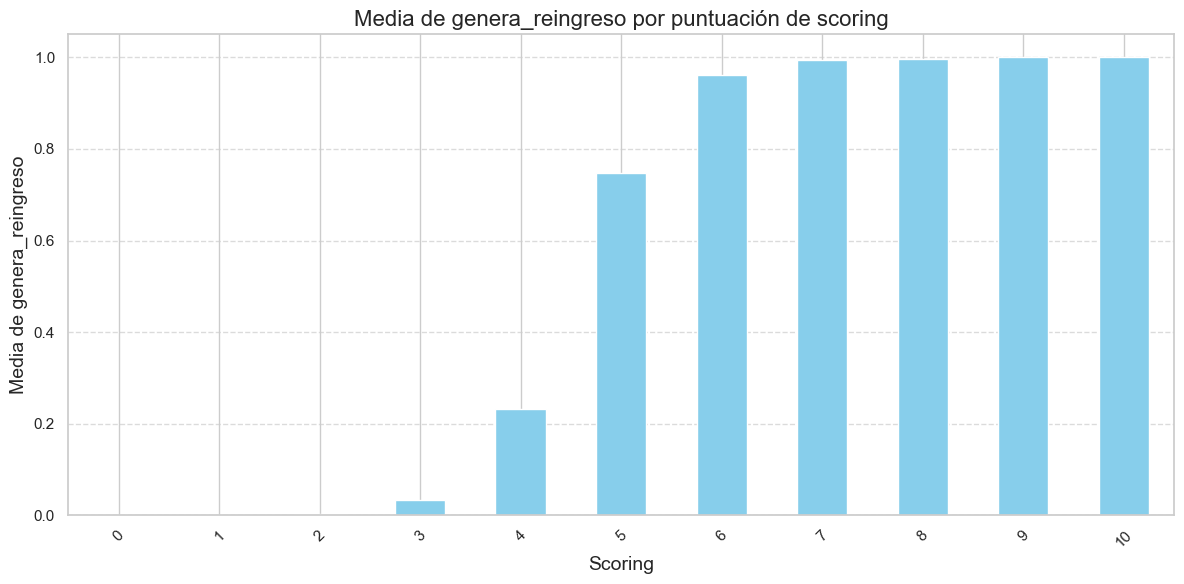

In [90]:
import matplotlib.pyplot as plt

# Convertir scoring a numérico (si no lo es)
risk['scoring'] = pd.to_numeric(risk['scoring'])

# Agrupar por `scoring` y calcular la media de `genera_reingreso`
scoring_avg = risk.groupby('scoring')['genera_reingreso'].mean().sort_index(ascending=True)

# Crear el gráfico de barras
plt.figure(figsize=(12, 6))
scoring_avg.plot(kind='bar', color='skyblue')

# Configurar título y etiquetas
plt.title('Media de genera_reingreso por puntuación de scoring', fontsize=16)
plt.xlabel('Scoring', fontsize=14)
plt.ylabel('Media de genera_reingreso', fontsize=14)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Mostrar el gráfico
plt.tight_layout()
plt.show()


## TRANSFORMACION A PRODUCCION

Ya hemos terminado el desarrollo de nuestro análisis.

Ahora tenemos que pasarlo a un código de producción.

Es decir un código que con la frecuencia que se quiera programar:

1 - Acceda a las fuentes originales de datos

2 - Aplique toda la limpieza y transformaciones de datos necesarias

3 - Calcule el risk score para cada paciente

4 - Escriba en el datamart de reingresos la información de salida limpia y enriquecida



Este códio de producción deberá ser lo más limpio posible ya que seguramente será exportado a un .py

Es decir, no tendrá:

* Nada de caracter exploratorio: gráficos, salidas por pantalla,  ...
* Nada de Markdown. Sí podemos usar comentarios con #

El script de producción solo contiene: procesos de input y output y procesos que cambian datos.



Está pensado ya para usar en el presente, es decir no debe incluir información del "futuro".



No debe crear recursos, debe usarlos en modo explotación.

Por ejemplo el Risk Score Card que hemos creado debemos dárselo ya hecho, por ejemplo pegando la función.

(Aunque sí lógicamente tiene calcular el dato para cada paciente)